# Clasificación de flores con redes neuronales convolucionales
## Notebook 2 de 2: evaluación y resultados

**Proyecto final – Electiva en Ingeniería de Software (redes neuronales)**
**Autor:** Juan Miguel López Rojas · **Docente:** Carlos Mario Paredes Valencia · Universidad de San Buenaventura Cali
**Repositorio:** https://github.com/DracoJM/clasificacion-flores-cnn

Este notebook carga los modelos entrenados en `01_datos_y_entrenamiento.ipynb` (la MobileNetV2 regularizada en sus dos versiones: con la base congelada y con ajuste fino) y produce **todos los números y figuras de resultados del informe**:

1. Análisis de sobreajuste: exactitud y pérdida en entrenamiento, validación y prueba.
2. Métricas en el conjunto de prueba (accuracy, precisión, recall y F1 macro) y por clase.
3. Matrices de confusión, análisis de errores y comparación pareada entre modelos (prueba de McNemar).
4. Ejemplos de predicciones y mapas Grad-CAM.
5. Comparación con trabajos científicos similares.

Usa las carpetas `datos/` (el conjunto descargado), `modelos/` (los cinco archivos `.keras`) y `resultados/` (`entrenamiento.json`), que genera el notebook 1. Como los modelos ya están guardados, se puede ejecutar sin volver a entrenar.

## 1. Librerías, datos y partición (idéntica a la del notebook 1)

In [1]:
import glob, json, os, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)

SEMILLA, IMG, LOTE = 42, 224, 32
CLASES_ES = ["Diente de león", "Margarita", "Tulipán", "Girasol", "Rosa"]
DATOS, MODELOS, RESULTADOS, FIGURAS = "datos", "modelos", "resultados", "resultados/figuras"
plt.rcParams.update({"font.size": 10, "savefig.dpi": 200, "savefig.bbox": "tight"})
AZUL, NARANJA, VERDE, GRIS = "#2F6DB5", "#E07B39", "#3E8E41", "#7F7F7F"

def cargar_dataset(carpeta):
    archivos = sorted(glob.glob(os.path.join(carpeta, "*.tfrecord*")))
    formato = {"image": tf.io.FixedLenFeature([], tf.string), "label": tf.io.FixedLenFeature([], tf.int64)}
    X, y = [], []
    for registro in tf.data.TFRecordDataset(archivos):
        ejemplo = tf.io.parse_single_example(registro, formato)
        img = tf.image.resize(tf.io.decode_jpeg(ejemplo["image"], channels=3), (IMG, IMG), antialias=True)
        X.append(tf.cast(tf.round(img), tf.uint8).numpy()); y.append(int(ejemplo["label"]))
    return np.stack(X), np.array(y)

X, y = cargar_dataset(DATOS)
X_ent, X_tmp, y_ent, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
X_val, X_pru, y_val, y_pru = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEMILLA)
print("Entrenamiento:", len(y_ent), "| Validación:", len(y_val), "| Prueba:", len(y_pru))

def a_dataset(X, y):
    return tf.data.Dataset.from_tensor_slices((X, y)).map(lambda a, b: (tf.cast(a, tf.float32), b)).batch(LOTE)

I0000 00:00:1794888022.454828     224 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794888022.461730     224 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794888023.232908     224 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794888025.218014     224 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794888025.221044     224 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


E0000 00:00:1794888026.695337     224 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
I0000 00:00:1794888026.807852     262 tf_record_dataset_op.cc:390] TFRecordDataset `buffer_size` is unspecified, default to 262144


Entrenamiento: 2569 | Validación: 550 | Prueba: 551


## 2. Carga de los modelos entrenados

In [2]:
# clave: (nombre para las tablas, archivo del modelo)
ARCHIVOS = {"CNN_base": ("CNN base (desde cero)", "CNN_base.keras"),
            "MobileNetV2_avance2": ("MobileNetV2 sin corregir (avance 2)", "MobileNetV2_avance2.keras"),
            "MobileNetV2_reg_congelada": ("MobileNetV2 regularizada, base congelada", "MobileNetV2_regularizada_fase1.keras"),
            "MobileNetV2_reg_ajuste_fino": ("MobileNetV2 regularizada, con ajuste fino", "MobileNetV2_regularizada.keras")}
NOMBRES = {n: v[0] for n, v in ARCHIVOS.items()}
FINAL = "MobileNetV2_reg_ajuste_fino"            # modelo final del proyecto
modelos = {n: tf.keras.models.load_model(os.path.join(MODELOS, v[1])) for n, v in ARCHIVOS.items()}
print("Modelo final:", NOMBRES[FINAL])
entrenamiento = json.load(open(os.path.join(RESULTADOS, "entrenamiento.json")))
for n, m in modelos.items():
    print(f"{NOMBRES[n]}: {m.count_params():,} parámetros")

Modelo final: MobileNetV2 regularizada, con ajuste fino
CNN base (desde cero): 391,141 parámetros
MobileNetV2 sin corregir (avance 2): 2,264,389 parámetros
MobileNetV2 regularizada, base congelada: 2,264,389 parámetros
MobileNetV2 regularizada, con ajuste fino: 2,264,389 parámetros


## 3. Análisis de sobreajuste: entrenamiento, validación y prueba

Cada modelo se evalúa, **sin aumento de datos ni Dropout**, sobre los tres subconjuntos. La **brecha** es la exactitud de entrenamiento menos la de validación (es la que se usa en el informe; también se calcula frente a prueba): cuanto más grande, más se ajusta el modelo a sus propios datos de entrenamiento. Una brecha pequeña no implica por sí sola mayor exactitud: hay que mirar las dos cosas.

In [3]:
generalizacion, probabilidades = {}, {}
for n, m in modelos.items():
    g = {}
    for parte, (Xp, yp) in (("entrenamiento", (X_ent, y_ent)), ("validacion", (X_val, y_val)), ("prueba", (X_pru, y_pru))):
        prob = m.predict(a_dataset(Xp, yp), verbose=0)
        exactitud = (prob.argmax(1) == yp).mean()
        perdida = -np.log(np.clip(prob[np.arange(len(yp)), yp], 1e-7, 1.0)).mean()    # entropía cruzada, sin el término L2
        g[parte] = {"accuracy": float(exactitud), "loss": float(perdida)}
    g["brecha_ent_val"] = g["entrenamiento"]["accuracy"] - g["validacion"]["accuracy"]
    g["brecha_ent_pru"] = g["entrenamiento"]["accuracy"] - g["prueba"]["accuracy"]
    generalizacion[n] = g

tabla_gen = pd.DataFrame([{
    "Modelo": NOMBRES[n],
    "Exactitud entrenamiento (%)": round(g["entrenamiento"]["accuracy"] * 100, 2),
    "Exactitud validación (%)": round(g["validacion"]["accuracy"] * 100, 2),
    "Exactitud prueba (%)": round(g["prueba"]["accuracy"] * 100, 2),
    "Brecha entren. − valid. (puntos)": round(g["brecha_ent_val"] * 100, 2),
    "Brecha entren. − prueba (puntos)": round(g["brecha_ent_pru"] * 100, 2),
    "Pérdida entrenamiento": round(g["entrenamiento"]["loss"], 4),
    "Pérdida validación": round(g["validacion"]["loss"], 4),
    "Pérdida prueba": round(g["prueba"]["loss"], 4),
} for n, g in generalizacion.items()]).set_index("Modelo")
tabla_gen

,Exactitud entrenamiento (%),Exactitud validación (%),Exactitud prueba (%),Brecha entren. − valid. (puntos),Brecha entren. − prueba (puntos),Pérdida entrenamiento,Pérdida validación,Pérdida prueba
Modelo,,,,,,,,
CNN base (desde cero),85.01,82.00,82.40,3.01,2.62,0.4220,0.5292,0.5331
MobileNetV2 sin corregir (avance 2),98.01,91.27,92.01,6.74,6.00,0.0597,0.2688,0.2403
"MobileNetV2 regularizada, base congelada",91.32,88.55,88.75,2.77,2.57,0.2610,0.3411,0.3260
"MobileNetV2 regularizada, con ajuste fino",97.28,91.82,91.83,5.46,5.44,0.0799,0.2378,0.2186


### 3.1 Selección del modelo final

El modelo final se elige **con el conjunto de validación**, no con el de prueba: entre las dos versiones de la MobileNetV2 regularizada se toma la de **mayor exactitud y menor pérdida de validación**. En una primera versión del análisis se había preferido la de menor brecha (base congelada); el criterio se revisó porque una brecha menor no garantiza un mejor desempeño: un modelo también reduce la brecha si simplemente aprende menos de sus datos de entrenamiento. La versión con la base congelada se conserva como comparación, porque muestra ese compromiso.

In [4]:
candidatos = ("MobileNetV2_reg_congelada", "MobileNetV2_reg_ajuste_fino")
for n in candidatos:
    g = generalizacion[n]
    print(f"{NOMBRES[n]}: exactitud de validación {g['validacion']['accuracy']*100:.2f} %, pérdida de validación {g['validacion']['loss']:.3f}, "
          f"brecha entren.−valid. {g['brecha_ent_val']*100:.2f} puntos")
mejor_exactitud = max(candidatos, key=lambda n: generalizacion[n]["validacion"]["accuracy"])
menor_perdida = min(candidatos, key=lambda n: generalizacion[n]["validacion"]["loss"])
assert mejor_exactitud == menor_perdida == FINAL, "El modelo final no es el mejor en validación"
print("Modelo final (mejor en validación):", NOMBRES[FINAL])
g, a2 = generalizacion[FINAL], generalizacion["MobileNetV2_avance2"]
print(f"Frente al avance 2: brecha {a2['brecha_ent_val']*100:.2f} -> {g['brecha_ent_val']*100:.2f} puntos; "
      f"exactitud de validación {a2['validacion']['accuracy']*100:.2f} -> {g['validacion']['accuracy']*100:.2f} %; "
      f"pérdida de validación {a2['validacion']['loss']:.3f} -> {g['validacion']['loss']:.3f}")

MobileNetV2 regularizada, base congelada: exactitud de validación 88.55 %, pérdida de validación 0.341, brecha entren.−valid. 2.77 puntos
MobileNetV2 regularizada, con ajuste fino: exactitud de validación 91.82 %, pérdida de validación 0.238, brecha entren.−valid. 5.46 puntos
Modelo final (mejor en validación): MobileNetV2 regularizada, con ajuste fino
Frente al avance 2: brecha 6.74 -> 5.46 puntos; exactitud de validación 91.27 -> 91.82 %; pérdida de validación 0.269 -> 0.238


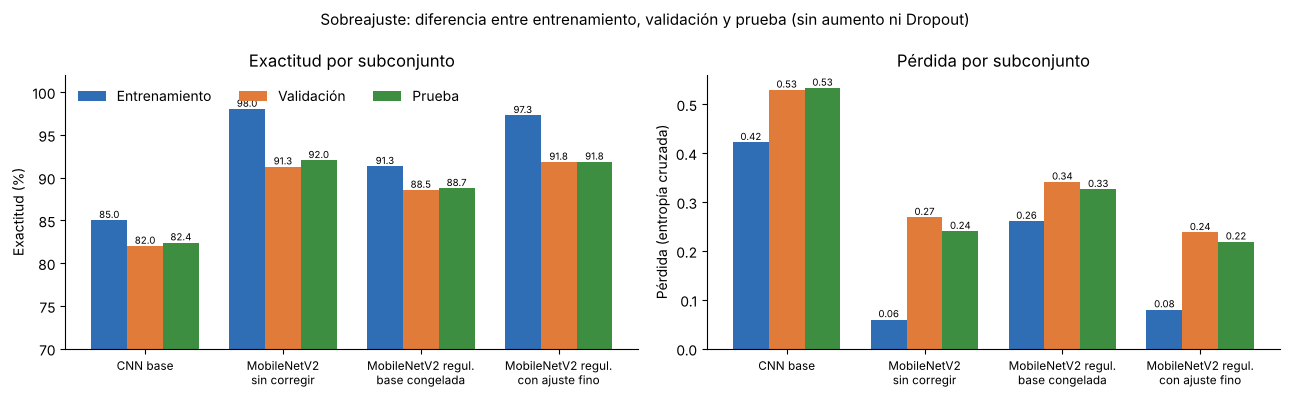

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(NOMBRES)); w = 0.26
etiquetas = ["CNN base", "MobileNetV2\nsin corregir", "MobileNetV2 regul.\nbase congelada", "MobileNetV2 regul.\ncon ajuste fino"]
for k, (parte, nombre, col) in enumerate((("entrenamiento", "Entrenamiento", AZUL), ("validacion", "Validación", NARANJA), ("prueba", "Prueba", VERDE))):
    v = [generalizacion[n][parte]["accuracy"] * 100 for n in NOMBRES]
    b = ax[0].bar(x + (k - 1) * w, v, w, label=nombre, color=col); ax[0].bar_label(b, fmt="%.1f", fontsize=7)
    v = [generalizacion[n][parte]["loss"] for n in NOMBRES]
    b = ax[1].bar(x + (k - 1) * w, v, w, label=nombre, color=col); ax[1].bar_label(b, fmt="%.2f", fontsize=7)
ax[0].set_ylim(70, 102); ax[0].set_ylabel("Exactitud (%)"); ax[0].set_title("Exactitud por subconjunto")
ax[1].set_ylabel("Pérdida (entropía cruzada)"); ax[1].set_title("Pérdida por subconjunto")
for a in ax:
    a.set_xticks(x, etiquetas, fontsize=8.5); a.spines[["top", "right"]].set_visible(False)
ax[0].legend(frameon=False, ncol=3, loc="upper left")
fig.suptitle("Sobreajuste: diferencia entre entrenamiento, validación y prueba (sin aumento ni Dropout)", fontsize=11)
fig.tight_layout(); fig.savefig(os.path.join(FIGURAS, "fig06_sobreajuste.png")); plt.show()

## 4. Métricas en el conjunto de prueba

El conjunto de prueba (551 imágenes) no se usó ni para entrenar ni para elegir la configuración: es una evaluación final con los pesos ya fijos. El tiempo por imagen es el de predecir las 551 imágenes en lotes de 32 en CPU, dividido entre 551 (se toma la pasada más rápida de tres); no es la latencia de una sola imagen. Se reportan *accuracy*, y precisión, *recall* y F1 **macro** (promedio simple de las cinco clases). El intervalo de confianza del 95 % de la exactitud se calcula con la aproximación normal de una proporción: ±1,96·√(p(1−p)/n).

In [6]:
def evaluar(modelo, Xp, yp):
    modelo.predict(a_dataset(Xp[:LOTE], yp[:LOTE]), verbose=0)          # calentamiento
    tiempos = []
    for _ in range(3):                                                  # se toma la pasada más rápida de tres
        t0 = time.time()
        prob = modelo.predict(a_dataset(Xp, yp), verbose=0)
        tiempos.append((time.time() - t0) / len(Xp) * 1000)
    ms = min(tiempos)
    pred = prob.argmax(1)
    acc = accuracy_score(yp, pred)
    return {"accuracy": acc, "ic95": 1.96 * np.sqrt(acc * (1 - acc) / len(yp)),
            "precision_macro": precision_score(yp, pred, average="macro"),
            "recall_macro": recall_score(yp, pred, average="macro"),
            "f1_macro": f1_score(yp, pred, average="macro"),
            "errores": int((pred != yp).sum()), "ms_por_imagen_cpu": ms,
            "parametros": int(modelo.count_params()),
            "matriz_confusion": confusion_matrix(yp, pred).tolist(),
            "reporte": classification_report(yp, pred, target_names=CLASES_ES, output_dict=True)}, prob

resultados = {}
for n, m in modelos.items():
    resultados[n], probabilidades[n] = evaluar(m, X_pru, y_pru)

pd.DataFrame([{
    "Modelo": NOMBRES[n], "Accuracy (%)": round(r["accuracy"] * 100, 2), "IC 95 % (± puntos)": round(r["ic95"] * 100, 2),
    "Precisión macro (%)": round(r["precision_macro"] * 100, 2), "Recall macro (%)": round(r["recall_macro"] * 100, 2),
    "F1 macro (%)": round(r["f1_macro"] * 100, 2), "Errores (de 551)": r["errores"],
    "Parámetros": f"{r['parametros']:,}", "ms / imagen (CPU)": round(r["ms_por_imagen_cpu"], 1),
} for n, r in resultados.items()]).set_index("Modelo")

,Accuracy (%),IC 95 % (± puntos),Precisión macro (%),Recall macro (%),F1 macro (%),Errores (de 551),Parámetros,ms / imagen (CPU)
Modelo,,,,,,,,
CNN base (desde cero),82.40,3.18,83.05,81.45,81.91,97,"391,141",4.7
MobileNetV2 sin corregir (avance 2),92.01,2.26,92.38,91.50,91.81,44,"2,264,389",6.0
"MobileNetV2 regularizada, base congelada",88.75,2.64,88.99,88.13,88.41,62,"2,264,389",6.4
"MobileNetV2 regularizada, con ajuste fino",91.83,2.29,91.62,91.76,91.66,45,"2,264,389",6.0


### 4.1 Métricas por clase del modelo final

In [7]:
rep = resultados[FINAL]["reporte"]
pd.DataFrame([{"Clase": c, "Precisión (%)": round(rep[c]["precision"] * 100, 2), "Recall (%)": round(rep[c]["recall"] * 100, 2),
               "F1 (%)": round(rep[c]["f1-score"] * 100, 2), "Imágenes": int(rep[c]["support"])} for c in CLASES_ES]).set_index("Clase")

,Precisión (%),Recall (%),F1 (%),Imágenes
Clase,,,,
Diente de león,96.24,94.81,95.52,135
Margarita,93.48,90.53,91.98,95
Tulipán,90.43,86.67,88.51,120
Girasol,91.82,96.19,93.95,105
Rosa,86.14,90.62,88.32,96


### 4.2 Matrices de confusión

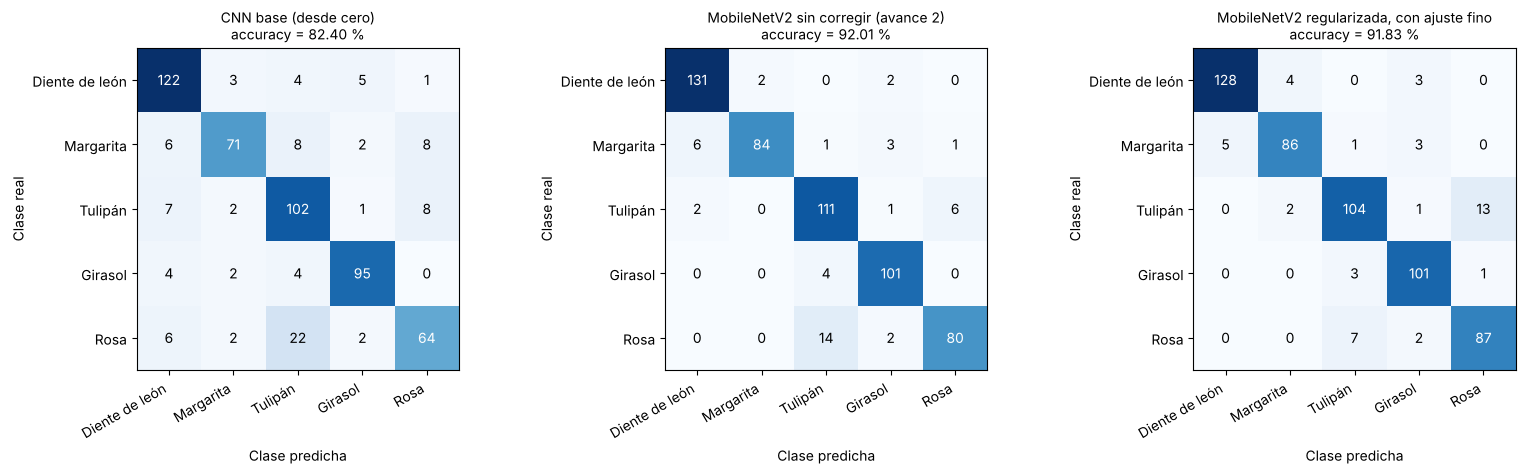

Confusiones más frecuentes del modelo final (real → predicha):
  Tulipán → Rosa: 13
  Rosa → Tulipán: 7
  Margarita → Diente de león: 5
  Diente de león → Margarita: 4
  Margarita → Girasol: 3

Matriz de confusión de MobileNetV2 regularizada, base congelada (filas: clase real; columnas: clase predicha)


,Diente de león,Margarita,Tulipán,Girasol,Rosa
Diente de león,128,3,0,4,0
Margarita,7,77,5,6,0
Tulipán,0,2,107,1,10
Girasol,2,1,4,98,0
Rosa,0,0,15,2,79


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, n in zip(ax, ("CNN_base", "MobileNetV2_avance2", FINAL)):
    cm = np.array(resultados[n]["matriz_confusion"])
    a.imshow(cm, cmap="Blues")
    for i in range(5):
        for j in range(5):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=10,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks(range(5), CLASES_ES, rotation=30, ha="right"); a.set_yticks(range(5), CLASES_ES)
    a.set_xlabel("Clase predicha"); a.set_ylabel("Clase real")
    a.set_title(f"{NOMBRES[n]}\naccuracy = {resultados[n]['accuracy']*100:.2f} %", fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(FIGURAS, "fig07_confusion.png")); plt.show()

cm = np.array(resultados[FINAL]["matriz_confusion"])
pares = sorted(((cm[i, j], CLASES_ES[i], CLASES_ES[j]) for i in range(5) for j in range(5) if i != j), reverse=True)[:5]
print("Confusiones más frecuentes del modelo final (real → predicha):")
for cantidad, real, predicha in pares:
    print(f"  {real} → {predicha}: {cantidad}")
otro = next(n for n in NOMBRES if n.startswith("MobileNetV2_reg") and n != FINAL)
print("\nMatriz de confusión de", NOMBRES[otro], "(filas: clase real; columnas: clase predicha)")
pd.DataFrame(resultados[otro]["matriz_confusion"], index=CLASES_ES, columns=CLASES_ES)

### 4.3 Análisis de los errores del modelo final

Se cuentan las confusiones más frecuentes (clase real → clase predicha) y qué parte del total de errores representan.

In [9]:
cm = np.array(resultados[FINAL]["matriz_confusion"]); total_err = int(cm.sum() - np.trace(cm))
pares_conf = sorted(((int(cm[i, j]), i, j) for i in range(5) for j in range(5) if i != j), reverse=True)
errores_final = {"total": total_err,
                 "confusiones": [{"real": CLASES_ES[i], "predicha": CLASES_ES[j], "casos": c} for c, i, j in pares_conf if c > 0],
                 "recall_por_clase": {CLASES_ES[i]: float(cm[i, i] / cm[i].sum()) for i in range(5)},
                 "errores_por_clase_real": {CLASES_ES[i]: int(cm[i].sum() - cm[i, i]) for i in range(5)}}
rosa, tuli = CLASES_ES.index("Rosa"), CLASES_ES.index("Tulipán")
errores_final["rosa_tulipan"] = int(cm[rosa, tuli] + cm[tuli, rosa])
print(f"Errores del modelo final: {total_err} de {len(y_pru)}")
print(f"Confusiones entre rosa y tulipán (en los dos sentidos): {errores_final['rosa_tulipan']} = {errores_final['rosa_tulipan'] / total_err * 100:.1f} % de los errores")
pd.DataFrame([{"Clase real": d["real"], "Clase predicha": d["predicha"], "Casos": d["casos"],
               "% de los errores": round(d["casos"] / total_err * 100, 1)} for d in errores_final["confusiones"][:8]])

Errores del modelo final: 45 de 551
Confusiones entre rosa y tulipán (en los dos sentidos): 20 = 44.4 % de los errores


,Clase real,Clase predicha,Casos,% de los errores
0,Tulipán,Rosa,13,28.9
1,Rosa,Tulipán,7,15.6
2,Margarita,Diente de león,5,11.1
3,Diente de león,Margarita,4,8.9
4,Girasol,Tulipán,3,6.7
5,Margarita,Girasol,3,6.7
6,Diente de león,Girasol,3,6.7
7,Rosa,Girasol,2,4.4


### 4.4 Comparación pareada entre modelos (prueba de McNemar)

Todos los modelos predicen las mismas 551 imágenes, así que la forma correcta de comparar dos modelos no es mirar si sus intervalos de confianza se solapan, sino contar las imágenes en las que **solo uno de los dos acierta**. La prueba exacta de McNemar calcula la probabilidad (valor p) de ver un reparto tan desigual si los dos modelos fueran igual de buenos. Un valor p menor que 0,05 indica una diferencia estadísticamente significativa en este conjunto de prueba; un valor p alto solo significa que no se detectó diferencia, no que los modelos sean equivalentes. Como se hacen cuatro comparaciones, se reporta también el valor p con la corrección de Bonferroni (multiplicado por cuatro). También se guardan las predicciones por imagen.

In [10]:
from scipy.stats import binomtest

pred_pru = {n: probabilidades[n].argmax(1) for n in modelos}
pares = [(FINAL, "CNN_base"), ("MobileNetV2_reg_ajuste_fino", "MobileNetV2_reg_congelada"),
         ("MobileNetV2_avance2", "MobileNetV2_reg_ajuste_fino"), ("MobileNetV2_avance2", "MobileNetV2_reg_congelada")]
mcnemar = []
for a, b in pares:
    ok_a, ok_b = pred_pru[a] == y_pru, pred_pru[b] == y_pru
    solo_a, solo_b = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    mcnemar.append({"modelo_a": a, "modelo_b": b, "solo_acierta_a": solo_a, "solo_acierta_b": solo_b,
                    "diferencia_puntos": float((ok_a.mean() - ok_b.mean()) * 100),
                    "p": float(binomtest(solo_a, solo_a + solo_b, 0.5).pvalue)})
for m in mcnemar:                                   # corrección de Bonferroni por hacer varias comparaciones
    m["p_bonferroni"] = min(1.0, m["p"] * len(mcnemar))

pd.DataFrame({"indice_en_prueba": np.arange(len(y_pru)), "clase_real": [CLASES_ES[k] for k in y_pru],
              **{"pred_" + n: [CLASES_ES[k] for k in pred_pru[n]] for n in modelos}}
             ).to_csv(os.path.join(RESULTADOS, "predicciones_prueba.csv"), index=False)

pd.DataFrame([{"Modelo A": NOMBRES[m["modelo_a"]], "Modelo B": NOMBRES[m["modelo_b"]], "Solo acierta A": m["solo_acierta_a"],
               "Solo acierta B": m["solo_acierta_b"], "Diferencia A − B (puntos)": round(m["diferencia_puntos"], 2),
               "Valor p (McNemar exacto)": round(m["p"], 4),
               "Valor p con Bonferroni": round(m["p_bonferroni"], 4)} for m in mcnemar])

,Modelo A,Modelo B,Solo acierta A,Solo acierta B,Diferencia A − B (puntos),Valor p (McNemar exacto),Valor p con Bonferroni
0,"MobileNetV2 regularizada, con ajuste fino",CNN base (desde cero),65,13,9.44,0.0000,0.0000
1,"MobileNetV2 regularizada, con ajuste fino","MobileNetV2 regularizada, base congelada",24,7,3.09,0.0033,0.0133
2,MobileNetV2 sin corregir (avance 2),"MobileNetV2 regularizada, con ajuste fino",11,10,0.18,1.0000,1.0000
3,MobileNetV2 sin corregir (avance 2),"MobileNetV2 regularizada, base congelada",22,4,3.27,0.0005,0.0021


## 5. Resultados cualitativos

### 5.1 Ejemplos de predicciones del modelo final
En verde los aciertos y en rojo los errores, con la probabilidad que el modelo asignó a su respuesta.

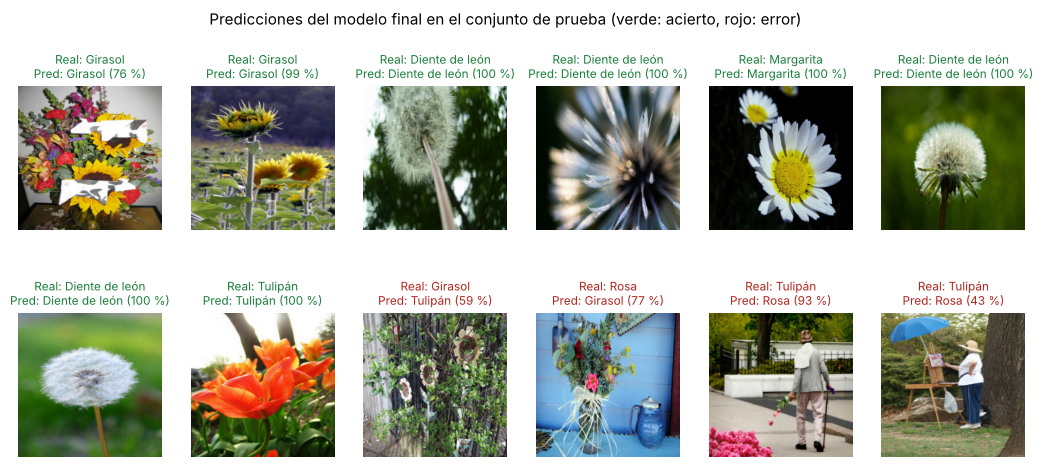

Probabilidad media de la clase elegida: aciertos 96.8 %, errores 74.0 %


In [11]:
p = probabilidades[FINAL]; pred = p.argmax(1)
aciertos, fallos = np.where(pred == y_pru)[0], np.where(pred != y_pru)[0]
rng = np.random.default_rng(1)
sel = list(rng.choice(aciertos, 8, replace=False)) + list(rng.choice(fallos, 4, replace=False))
fig, ax = plt.subplots(2, 6, figsize=(13, 5.4))
for a, i in zip(ax.ravel(), sel):
    a.imshow(X_pru[i]); a.axis("off")
    a.set_title(f"Real: {CLASES_ES[y_pru[i]]}\nPred: {CLASES_ES[pred[i]]} ({p[i].max()*100:.0f} %)", fontsize=8.5,
                color="#1B7F3B" if pred[i] == y_pru[i] else "#B3261E")
fig.suptitle("Predicciones del modelo final en el conjunto de prueba (verde: acierto, rojo: error)", fontsize=11)
fig.savefig(os.path.join(FIGURAS, "fig08_predicciones.png")); plt.show()
print(f"Probabilidad media de la clase elegida: aciertos {p.max(1)[pred == y_pru].mean()*100:.1f} %, "
      f"errores {p.max(1)[pred != y_pru].mean()*100:.1f} %")

### 5.2 Mapas Grad-CAM
Grad-CAM colorea las zonas de la imagen que más pesaron en la decisión del modelo (rojo = más influencia). Da un indicio de si la red se apoya en la flor o en el fondo. Se muestra un acierto por clase, así que es evidencia cualitativa limitada: no descarta que en otras imágenes, o en los errores, el fondo influya.

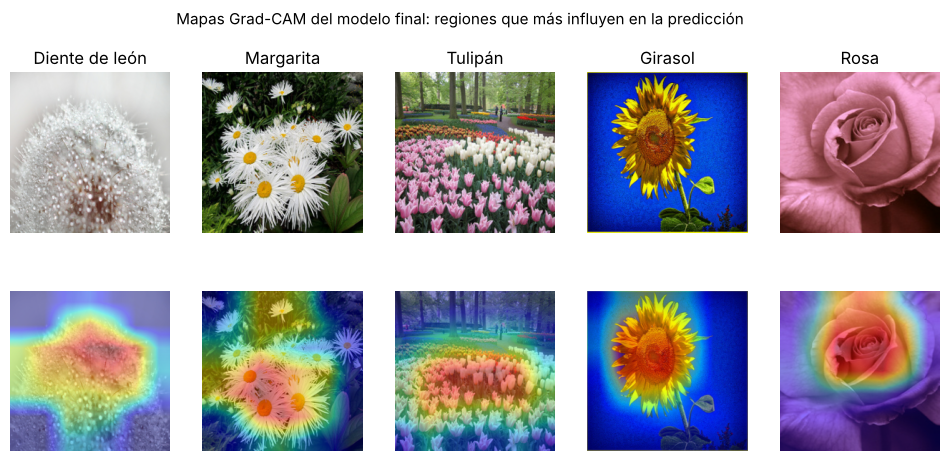

In [12]:
m = modelos[FINAL]
base = next(c for c in m.layers if isinstance(c, tf.keras.Model) and "mobilenet" in c.name)
extractor = tf.keras.Model(base.inputs, base.get_layer("out_relu").output)
gap = next(c for c in m.layers if isinstance(c, tf.keras.layers.GlobalAveragePooling2D))
densa = m.layers[-1]

def grad_cam(imagen, clase):
    x = tf.cast(imagen[None], tf.float32) / 127.5 - 1.0
    with tf.GradientTape() as cinta:
        mapa = extractor(x, training=False)
        cinta.watch(mapa)
        salida = densa(gap(mapa))[:, clase]
    grad = cinta.gradient(salida, mapa)[0]
    pesos = tf.reduce_mean(grad, axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(mapa[0] * pesos, axis=-1)).numpy()
    cam = cam / (cam.max() + 1e-8)
    return tf.image.resize(cam[..., None], (IMG, IMG)).numpy()[..., 0]

rng = np.random.default_rng(2)
sel = [rng.choice(np.where((y_pru == c) & (pred == c))[0]) for c in range(5)]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.2))
for k, i in enumerate(sel):
    ax[0, k].imshow(X_pru[i]); ax[0, k].axis("off"); ax[0, k].set_title(CLASES_ES[y_pru[i]])
    ax[1, k].imshow(X_pru[i]); ax[1, k].imshow(grad_cam(X_pru[i], pred[i]), cmap="jet", alpha=0.45); ax[1, k].axis("off")
fig.suptitle("Mapas Grad-CAM del modelo final: regiones que más influyen en la predicción", fontsize=11)
fig.savefig(os.path.join(FIGURAS, "fig09_gradcam.png")); plt.show()

## 6. Comparación con trabajos científicos similares

Se compara el modelo final con artículos de revista que clasifican las **mismas cinco clases de flores** (margarita, diente de león, rosa, girasol y tulipán); uno de ellos añade dos clases más. Los valores se tomaron de cada artículo. Los trabajos difieren en número de imágenes, partición y tipo de métrica (prueba o validación), así que las diferencias son **descriptivas**: no prueban que un método sea mejor que otro.

In [13]:
r = resultados[FINAL]
# (trabajo, datos, clases, modelo, métrica reportada, exactitud en %)
literatura = [
    ("Toğaçar et al. (2020)", "Conjunto de 5 clases de flores", 5, "Características de CNN + selección + SVM", "Según autores", 98.91),
    ("Wang et al. (2022)", "Flores (incluye TF Flowers)", 5, "Selección dinámica entre 13 clasificadores MobileNet", "Prueba", 95.50),
    ("Mufidatuzzainiya y Faisal (2025)", "Kaggle, 4.242 imágenes", 5, "EfficientNetB3", "Validación", 94.00),
    ("Praskatama et al. (2024)", "Kaggle, 4.317 imágenes (60/10/30)", 5, "DenseNet con ajuste fino + SMOTE", "Prueba", 93.92),
    ("Praskatama et al. (2024)", "Kaggle, 4.317 imágenes (60/10/30)", 5, "MobileNet con ajuste fino + SMOTE", "Prueba", 88.34),
    ("Oralbekova et al. (2026)", "5 clases + 2 propias, 4.713 imágenes", 7, "MobileNetV2", "Prueba", 87.10),
    ("Praskatama et al. (2024)", "Kaggle, 4.317 imágenes (60/10/30)", 5, "CNN desde cero", "Prueba", 74.61),
]
filas = [{"Trabajo": t, "Datos": d, "Clases": c, "Modelo": mo, "Métrica": me, "Accuracy (%)": a,
          "Diferencia con este trabajo (puntos)": round(r["accuracy"] * 100 - a, 2)} for t, d, c, mo, me, a in literatura]
for etiqueta, n in (("Este trabajo (modelo final)", FINAL), ("Este trabajo", otro), ("Este trabajo", "CNN_base")):
    filas.append({"Trabajo": etiqueta, "Datos": "tf_flowers, 3.670 imágenes (70/15/15)", "Clases": 5, "Modelo": NOMBRES[n], "Métrica": "Prueba",
                  "Accuracy (%)": round(resultados[n]["accuracy"] * 100, 2),
                  "Diferencia con este trabajo (puntos)": round((r["accuracy"] - resultados[n]["accuracy"]) * 100, 2)})
print(f"Este trabajo (modelo final): {r['accuracy']*100:.2f} % ± {r['ic95']*100:.2f} (IC 95 %: {(r['accuracy']-r['ic95'])*100:.2f} – {(r['accuracy']+r['ic95'])*100:.2f} %)")
print("Las diferencias se calculan con los valores sin redondear.")
pd.DataFrame(filas).sort_values("Accuracy (%)", ascending=False).set_index("Trabajo")

Este trabajo (modelo final): 91.83 % ± 2.29 (IC 95 %: 89.55 – 94.12 %)
Las diferencias se calculan con los valores sin redondear.


,Datos,Clases,Modelo,Métrica,Accuracy (%),Diferencia con este trabajo (puntos)
Trabajo,,,,,,
Toğaçar et al. (2020),Conjunto de 5 clases de flores,5,Características de CNN + selección + SVM,Según autores,98.91,-7.08
Wang et al. (2022),Flores (incluye TF Flowers),5,Selección dinámica entre 13 clasificadores Mob...,Prueba,95.50,-3.67
Mufidatuzzainiya y Faisal (2025),"Kaggle, 4.242 imágenes",5,EfficientNetB3,Validación,94.00,-2.17
Praskatama et al. (2024),"Kaggle, 4.317 imágenes (60/10/30)",5,DenseNet con ajuste fino + SMOTE,Prueba,93.92,-2.09
Este trabajo (modelo final),"tf_flowers, 3.670 imágenes (70/15/15)",5,"MobileNetV2 regularizada, con ajuste fino",Prueba,91.83,0.00
Este trabajo,"tf_flowers, 3.670 imágenes (70/15/15)",5,"MobileNetV2 regularizada, base congelada",Prueba,88.75,3.09
Praskatama et al. (2024),"Kaggle, 4.317 imágenes (60/10/30)",5,MobileNet con ajuste fino + SMOTE,Prueba,88.34,3.49
Oralbekova et al. (2026),"5 clases + 2 propias, 4.713 imágenes",7,MobileNetV2,Prueba,87.10,4.73
Este trabajo,"tf_flowers, 3.670 imágenes (70/15/15)",5,CNN base (desde cero),Prueba,82.40,9.44


## 7. Guardado de los resultados

In [14]:
json.dump({"final": FINAL, "generalizacion": generalizacion, "resultados": resultados,
           "mcnemar": mcnemar, "errores_final": errores_final,
           "literatura": [{"trabajo": t, "datos": d, "clases": c, "modelo": mo, "metrica": me, "accuracy": a} for t, d, c, mo, me, a in literatura]},
          open(os.path.join(RESULTADOS, "resultados.json"), "w"), indent=1, ensure_ascii=False, default=float)
np.savez_compressed(os.path.join(RESULTADOS, "muestras_resumen.npz"), imgs=X_pru[sel])   # una imagen por clase para el resumen gráfico del informe
print("Guardado resultados/resultados.json y las figuras en", FIGURAS)

print("\nResumen final")
for n, g in generalizacion.items():
    print(f"- {NOMBRES[n]}: entrenamiento {g['entrenamiento']['accuracy']*100:.2f} %, validación {g['validacion']['accuracy']*100:.2f} %, "
          f"prueba {g['prueba']['accuracy']*100:.2f} % | brecha entren.−valid. {g['brecha_ent_val']*100:.2f} puntos | "
          f"F1 macro en prueba {resultados[n]['f1_macro']*100:.2f} %")
print(f"Modelo final: {NOMBRES[FINAL]}")

Guardado resultados/resultados.json y las figuras en resultados/figuras

Resumen final
- CNN base (desde cero): entrenamiento 85.01 %, validación 82.00 %, prueba 82.40 % | brecha entren.−valid. 3.01 puntos | F1 macro en prueba 81.91 %
- MobileNetV2 sin corregir (avance 2): entrenamiento 98.01 %, validación 91.27 %, prueba 92.01 % | brecha entren.−valid. 6.74 puntos | F1 macro en prueba 91.81 %
- MobileNetV2 regularizada, base congelada: entrenamiento 91.32 %, validación 88.55 %, prueba 88.75 % | brecha entren.−valid. 2.77 puntos | F1 macro en prueba 88.41 %
- MobileNetV2 regularizada, con ajuste fino: entrenamiento 97.28 %, validación 91.82 %, prueba 91.83 % | brecha entren.−valid. 5.46 puntos | F1 macro en prueba 91.66 %
Modelo final: MobileNetV2 regularizada, con ajuste fino
